# Yellow rust yield loss in Egyptian wheat cultivars (Sharkiya)

This notebook reproduces, with simpest, the FraNchEstYN R vignette
"Yellow rust on wheat in Egypt" (`vignettes/case-study-egypt-yellow-rust.Rmd`
in [GeoModelLab/FraNchEstYN](https://github.com/GeoModelLab/FraNchEstYN);
a rendered copy is `estimating_yield_loss.html` in this folder). It is the
first simpest case where the simulated yield loss can be set against a
**measured** loss.

**The trial.** Omara, El-Naggar, Abd El Malik and Ketta (2016), *Losses
assessment in some Egyptian wheat cultivars caused by stripe rust pathogen
(Puccinia striiformis)*, Egypt. J. Phytopathol. 44(1):191–203
(`SharkiyaData/paper/`; the R package cites it as 2018). Seven bread-wheat
cultivars were grown at Kafr El-Hamam Agricultural Research Station,
Sharkiya (30.615 N, 31.515 E), in 2013/14 and 2014/15, in a split-plot
design: each cultivar was either **protected** (three sprays of Sumi-8 from
disease onset) or **infected** (spreader rows inoculated at booting). Stripe
(yellow) rust severity was scored weekly as percent leaf area with pustules
(modified Cobb scale, Peterson et al. 1948), and grain yield was measured in
both treatments. The measured loss is the paper's "estimated loss",
`(1 − Y_infected / Y_protected) × 100` (Calpouzos et al. 1976).

**The workflow** has the vignette's three steps:

1. **Crop**: calibrate the crop on the most susceptible cultivar (Sids-12)
   against light interception and the protected-plot yield, with the disease
   switched off.
2. **Disease**: keep the crop fixed and calibrate the yellow-rust parameters on
   Sids-12 against severity and the infected-plot yield, with the light
   stealer as the only damage mechanism.
3. **Cultivars**: keep the disease fixed and fit, per cultivar, only the
   radiation use efficiency and the varietal resistance.

A last section compares simulated and measured loss for all fourteen
cultivar-seasons.

## Where this notebook differs from the R vignette

- **Optimizer.** 999 Optuna (TPE) trials per calibration, in reproducible
  batches of 5, in place of the R package's 999 iterations.
- **Harvest observations after simulated maturity are scored.** The yields
  are dated DOY 135 (15 May), a placeholder of the R dataset: the paper gives
  no harvest date. The model stops at maturity, and by default (as in the C#
  model) an observation dated after it is silently dropped from the objective.
  Here `score_harvest_after_maturity=True` compares it with the season's final
  yield, which is the yield a harvest measures.
- **Phenology is fixed to a mid-May harvest instead of calibrated.** The
  vignette widens the `CycleLength` bounds to 3000–4500 °C d to get a harvest
  around mid-May. The data hold no date of maturity, so a calibrated
  `CycleLength` is not pinned by anything: in a trial run it drifted to a crop
  that matured in September. Here `CycleLength` is set to the thermal time from
  sowing to DOY 135, and `TbaseCrop` keeps its canonical value.

## What the results can and cannot support

- **The simulated loss is fitted, not predicted.** Both yields of every
  cultivar-season are calibration targets (step 1 the protected yield of
  Sids-12, step 2 its infected yield, step 3 both yields of each cultivar).
  The comparison in section 6 is a check of how well one parameter set per
  cultivar can reproduce both seasons, not an independent test.
- **Sowing date is assumed.** DOY 300 (27 October), as in the vignette; the
  paper does not give it.
- **The `fint` column is a placeholder.** It holds 1.0 on DOY 91 and 0.3 on
  DOY 135 for every cultivar and season, not a measurement.
- **Weather is gridded.** NASA POWER (MERRA-2) daily Tmax, Tmin and rain, the
  vignette's query. Radiation is not in it and is estimated from the
  temperature range (Hargreaves–Samani); hourly humidity and leaf wetness are
  synthesised from the daily values.

In [1]:
import copy
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from simpest.models import franchestyn as fr
from simpest.models import fr_diagnostics as diag

DATA = Path("SharkiyaData")
START_YEAR, END_YEAR = 2013, 2015   # as in the vignette: sowings in 2013 and 2014
SEASONS = [2013, 2014]              # GrowingSeason = sowing year
SUSCEPTIBLE = "sids12"              # the most susceptible cultivar (paper, Table 1)
HARVEST_DOY = 135                   # date of the yield observations in the dataset

# Calibration settings shared by the three steps.
CALIB = dict(optimizer="optuna", n_trials=999, seed=1, n_jobs=5)

## 1. Data

Everything is read from `SharkiyaData/`, laid out like the Indiana data folder:

| file | content | source |
|---|---|---|
| `site/site.csv` | latitude, sowing DOY, CO₂ per season (also the torchcrop site table) | written by `tools/fetch_power_torchcrop_dataset.py`; only the latitude is used here |
| `weather/sharkiya_2013_2015.csv` | daily `tmax`, `tmin`, `prec`, 2013–2015 | NASA POWER daily API, `T2M_MAX`, `T2M_MIN`, `PRECTOTCORR`, the vignette's query |
| `management/management.csv` | crop, sowing DOY 300 for all years | the vignette's assumption |
| `disease/disease.csv` | severity (%) per cultivar and date, `fint` placeholder | `data-raw/reference_egypt.csv` of the R package, digitised from the paper |
| `yield/yield.csv` | protected (`yieldAttainable`) and infected (`yieldActual`) grain yield, kg ha⁻¹ | same file; the paper's ardab feddan⁻¹ × 150 kg / 0.42 ha (Tables 2 and 3) |

In [2]:
site = pd.read_csv(DATA / "site" / "site.csv").iloc[0]
weather_df = pd.read_csv(DATA / "weather" / "sharkiya_2013_2015.csv")
management_df = pd.read_csv(DATA / "management" / "management.csv")
disease_obs = pd.read_csv(DATA / "disease" / "disease.csv")
yield_obs = pd.read_csv(DATA / "yield" / "yield.csv")

# One reference table, as FraNchEstYN expects it: severity, fint and yields by year and DOY.
ref_df = disease_obs.merge(yield_obs, on=["site", "variety", "year", "DOY"], how="left")

yield_obs["season"] = yield_obs["year"] - 1     # yields are reported in the harvest year
yield_obs["loss_measured"] = (1 - yield_obs["yieldActual"] / yield_obs["yieldAttainable"]) * 100
VARIETIES = list(disease_obs["variety"].unique())

display(weather_df.head(3))
display(management_df)
yield_obs.pivot(index="variety", columns="season", values="loss_measured").round(1).loc[VARIETIES]

,date,tmax,tmin,prec
0,2013-01-01,20.49,7.10,0.00
1,2013-01-02,21.39,6.21,0.00
2,2013-01-03,22.32,9.08,0.07


,crop,variety,resistance,sowingDOY,year
0,wheat,Generic,0,300,All


season,2013,2014
variety,,
sids12,55.4,58.3
gem11,53.4,57.0
gem7,42.8,46.6
sids13,30.8,35.4
sids1,35.0,39.4
gem9,24.1,26.9
gem10,18.9,23.9


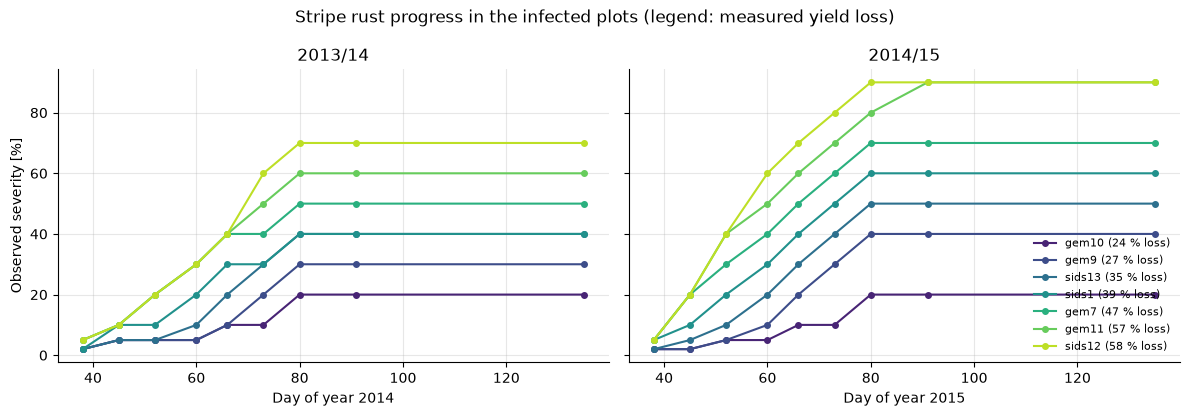

In [3]:
# Observed severity per cultivar and season. Cultivars are ordered by measured
# loss (2013/14), so the colour ramp runs from the least to the most damaged one.
order = (yield_obs[yield_obs["season"] == 2013].sort_values("loss_measured")["variety"].tolist())
colors = dict(zip(order, plt.get_cmap("viridis")(np.linspace(0.1, 0.9, len(order)))))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, season in zip(axes, SEASONS):
    for variety in order:
        obs = disease_obs[(disease_obs["variety"] == variety) & (disease_obs["year"] == season + 1)]
        loss = yield_obs.query("variety == @variety and season == @season")["loss_measured"].iloc[0]
        ax.plot(obs["DOY"], obs["disease"], marker="o", ms=4, color=colors[variety],
                label=f"{variety} ({loss:.0f} % loss)")
    ax.set_title(f"{season}/{season + 1 - 2000:02d}")
    ax.set_xlabel(f"Day of year {season + 1}")
    ax.grid(alpha=0.3)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
axes[0].set_ylabel("Observed severity [%]")
axes[1].legend(frameon=False, fontsize=8, loc="lower right")
fig.suptitle("Stripe rust progress in the infected plots (legend: measured yield loss)")
fig.tight_layout()
plt.show()

## 2. Shared run settings

All runs use the internal FraNchEstYN crop model (`crop_model_df=None`), daily
weather and no fungicide model: the protected plots are represented by the
attainable (disease-free) yield, not by a simulated spray. The management
table is filtered by cultivar, so each run gets it with that cultivar's name.

In [4]:
def make_config(variety, **settings):
    """Run settings shared by every run in this notebook."""
    return fr.FranchestynConfig(
        site="Sharkiya", variety=variety, disease="disease", fungicide_type=None,
        latitude=float(site.LATITUDE), score_harvest_after_maturity=True, **settings,
    )


def run(config, variety):
    return fr.run_franchestyn(
        START_YEAR, END_YEAR, config, weather_df, management_df.assign(variety=variety), None, ref_df,
    )


def obs_dates(df):
    return diag.reference_dates(df)

## 3. Step 1 — crop calibration (Sids-12, no disease)

**Phenology.** The harvest is put on DOY 135, the date of the yield
observations, which matches the vignette's aim of a harvest around mid-May.
`CycleLength` is the thermal time the model accumulates from sowing to that
day, read from a crop-only run with a cycle too long to end, and averaged over
the two seasons. `TbaseCrop` keeps its canonical value
(`fr_crop_parameters.json`, wheat).

**Calibrated.** The remaining crop parameters flagged for calibration in the
canonical wheat set: `FloweringStart`, `HalfIntGrowth`, `HalfIntSenescence`,
`SlopeGrowth`, `SlopeSenescence` and `PartitioningMaximum`. The targets are
the two protected-plot yields of Sids-12 and the `fint` placeholders.

In [5]:
probe = make_config(SUSCEPTIBLE, disease_type=None, is_calibration=False)
probe.crop_parameters["CycleLength"].update(value=1e5, max=1e5)
probe_sim = diag.simulation_frame(run(probe, SUSCEPTIBLE))
gdd_at_harvest = probe_sim.loc[probe_sim["Date"].dt.dayofyear == HARVEST_DOY, "GrowingDegreeDays"]
cycle_length = float(gdd_at_harvest.mean())
print("Thermal time sowing -> DOY 135 per season:", gdd_at_harvest.round(0).tolist(),
      f"-> CycleLength = {cycle_length:.0f} degC d")

crop_cfg = make_config(SUSCEPTIBLE, disease_type=None, calibration_variable="crop", **CALIB)
crop_cfg.crop_parameters["CycleLength"].update(value=cycle_length, calibration=False)
fr.deactivate_calibration(crop_cfg.crop_parameters, ["TbaseCrop"])

crop_res = run(crop_cfg, SUSCEPTIBLE)
crop_best = crop_res["outputs"]["summary"]["best_params"]
fr.apply_best_params(crop_cfg, crop_best)
print("Objective (RMSE):", crop_res["outputs"]["summary"]["rmse"])
diag.bound_check(crop_best, {"crop": crop_cfg.crop_parameters}).round(4)

Thermal time sowing -> DOY 135 per season: [3695.0, 3562.0] -> CycleLength = 3628 degC d
- Calibrating 6 using Optuna (TPE), n_trials=999.
- Parameters:
['crop_FloweringStart', 'crop_HalfIntGrowth', 'crop_HalfIntSenescence', 'crop_SlopeGrowth', 'crop_SlopeSenescence', 'crop_PartitioningMaximum']
- Evaluating trials in batches of 5 across 5 worker processes.


Best RMSE: 1.0940
{'crop_FloweringStart': 83.09139224763437, 'crop_HalfIntGrowth': 22.274986633418795, 'crop_HalfIntSenescence': 96.4050989785669, 'crop_SlopeGrowth': 0.018010562704691258, 'crop_SlopeSenescence': 0.019325205204912585, 'crop_PartitioningMaximum': 0.80005811235369}


Objective (RMSE): 1.094


,value,min,max,position,at_bound
parameter,,,,,
crop_FloweringStart,83.0914,50.000,85.00,0.9455,
crop_HalfIntGrowth,22.2750,20.000,35.00,0.1517,
crop_HalfIntSenescence,96.4051,50.000,99.00,0.9470,
crop_SlopeGrowth,0.0180,0.001,0.02,0.8953,
crop_SlopeSenescence,0.0193,0.001,0.07,0.2656,
crop_PartitioningMaximum,0.8001,0.800,1.00,0.0003,lower


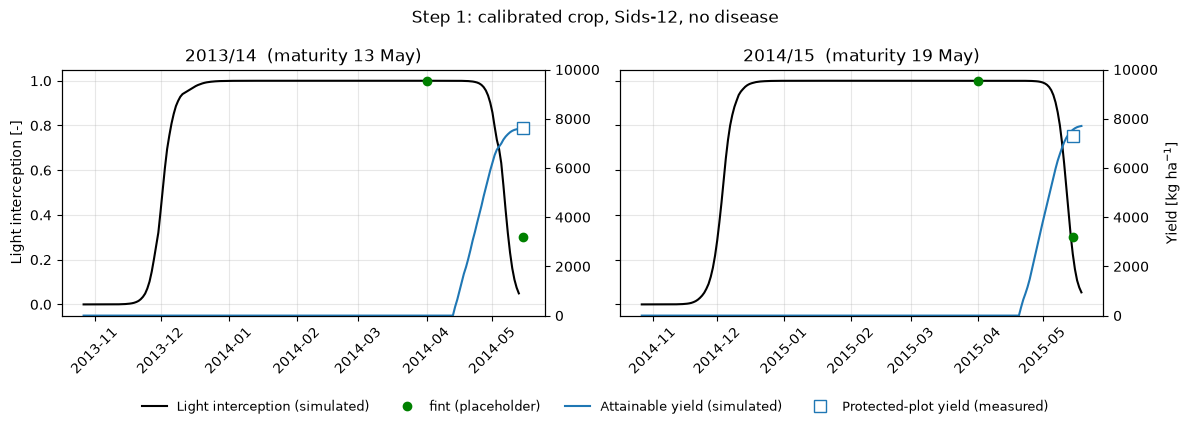

In [6]:
crop_sim = diag.simulation_frame(crop_res)
sus_ref = ref_df[ref_df["variety"] == SUSCEPTIBLE]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, season in zip(axes, SEASONS):
    s = crop_sim[crop_sim["GrowingSeason"] == season]
    r = sus_ref[sus_ref["year"] == season + 1]
    ax.plot(s["Date"], s["LightInterception"], color="black", lw=1.5, label="Light interception (simulated)")
    fi = r.dropna(subset=["fint"])
    ax.plot(obs_dates(fi), fi["fint"], "o", color="green", label="fint (placeholder)")
    ax2 = ax.twinx()
    ax2.plot(s["Date"], s["YieldAttainable"], color="#1f77b4", lw=1.5, label="Attainable yield (simulated)")
    y = r.dropna(subset=["yieldAttainable"])
    ax2.plot(obs_dates(y), y["yieldAttainable"], "s", color="#1f77b4", mfc="white", ms=8,
             label="Protected-plot yield (measured)")
    ax2.set_ylim(0, 10000)
    ax.set_title(f"{season}/{season + 1 - 2000:02d}  (maturity {s['Date'].max():%d %b})")
    ax.tick_params(axis="x", rotation=45)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Light interception [-]")
ax2.set_ylabel("Yield [kg ha$^{-1}$]")
handles = axes[0].get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
fig.legend(handles, [h.get_label() for h in handles], loc="lower center", ncol=4, frameon=False, fontsize=9)
fig.suptitle("Step 1: calibrated crop, Sids-12, no disease")
fig.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()

## 4. Step 2 — disease calibration (Sids-12)

The crop is fixed at step 1. Following the vignette, the damage pathways other
than the light stealer are switched off, to avoid fitting four damage
coefficients to two yields: `AssimilateSappersDamage`, `RUEreducerDamage` and
`SenescenceAcceleratorDamage` are set to 0 and not calibrated, and
`OuterInoculumShapeRelease` is set to 1 (all four values from the vignette).
The other yellow-rust parameters flagged in `fr_disease_parameters.json`,
including `LightStealerDamage`, are calibrated against the severity of
Sids-12 and its infected-plot yield (`calibration_variable="disease"`).

In [7]:
dis_cfg = make_config(SUSCEPTIBLE, disease_type="yellow_rust", calibration_variable="disease", **CALIB)
dis_cfg.crop_parameters = copy.deepcopy(crop_cfg.crop_parameters)
fr.deactivate_calibration(dis_cfg.crop_parameters, list(dis_cfg.crop_parameters))
for name in ("AssimilateSappersDamage", "RUEreducerDamage", "SenescenceAcceleratorDamage"):
    dis_cfg.disease_parameters[name].update(value=0.0, calibration=False)   # vignette, step 2
dis_cfg.disease_parameters["OuterInoculumShapeRelease"]["value"] = 1.0       # vignette, step 2

dis_res = run(dis_cfg, SUSCEPTIBLE)
dis_best = dis_res["outputs"]["summary"]["best_params"]
fr.apply_best_params(dis_cfg, dis_best)
print("Objective (RMSE):", dis_res["outputs"]["summary"]["rmse"])
diag.bound_check(dis_best, {"disease": dis_cfg.disease_parameters}).round(3)

- Calibrating 17 using Optuna (TPE), n_trials=999.
- Parameters:
['disease_OuterInoculumMax', 'disease_PathogenSpread', 'disease_WetnessDurationOptimum', 'disease_WetnessDurationMinimum', 'disease_DryCriticalInterruption', 'disease_Tmin', 'disease_Topt', 'disease_Tmax', 'disease_RelativeHumidityCritical', 'disease_Rain50Detachment', 'disease_RelativeHumidityNotLimiting', 'disease_HydroThermalTimeOnset', 'disease_CyclePercentageOnset', 'disease_LatencyDuration', 'disease_SporulationDuration', 'disease_LightStealerDamage', 'disease_OuterInoculumShapeParameter']
- Evaluating trials in batches of 5 across 5 worker processes.


Best RMSE: 8.2350
{'disease_OuterInoculumMax': 0.13329288874405287, 'disease_PathogenSpread': 0.21595033992022894, 'disease_WetnessDurationOptimum': 19.160254641547176, 'disease_WetnessDurationMinimum': 3.192188667337243, 'disease_DryCriticalInterruption': 19.62629891442335, 'disease_Tmin': 2.926554390001315, 'disease_Topt': 11.70199995139115, 'disease_Tmax': 23.053222786904755, 'disease_RelativeHumidityCritical': 50.74147719433561, 'disease_Rain50Detachment': 0.6980414173497937, 'disease_RelativeHumidityNotLimiting': 88.65901387076735, 'disease_HydroThermalTimeOnset': 13.426842721878396, 'disease_CyclePercentageOnset': 18.60858042464352, 'disease_LatencyDuration': 11.88019969608977, 'disease_SporulationDuration': 27.860870011201744, 'disease_LightStealerDamage': 0.5962234084509238, 'disease_OuterInoculumShapeParameter': 0.4429763224468679}
Objective (RMSE): 8.235


,value,min,max,position,at_bound
parameter,,,,,
disease_OuterInoculumMax,0.133,0.01,0.14,0.948,
disease_PathogenSpread,0.216,0.01,0.50,0.420,
disease_WetnessDurationOptimum,19.160,10.00,20.00,0.916,
disease_WetnessDurationMinimum,3.192,3.00,10.00,0.027,lower
disease_DryCriticalInterruption,19.626,6.00,24.00,0.757,
disease_Tmin,2.927,0.00,8.00,0.366,
disease_Topt,11.702,10.00,18.00,0.213,
disease_Tmax,23.053,18.00,25.00,0.722,
disease_RelativeHumidityCritical,50.741,50.00,75.00,0.030,lower


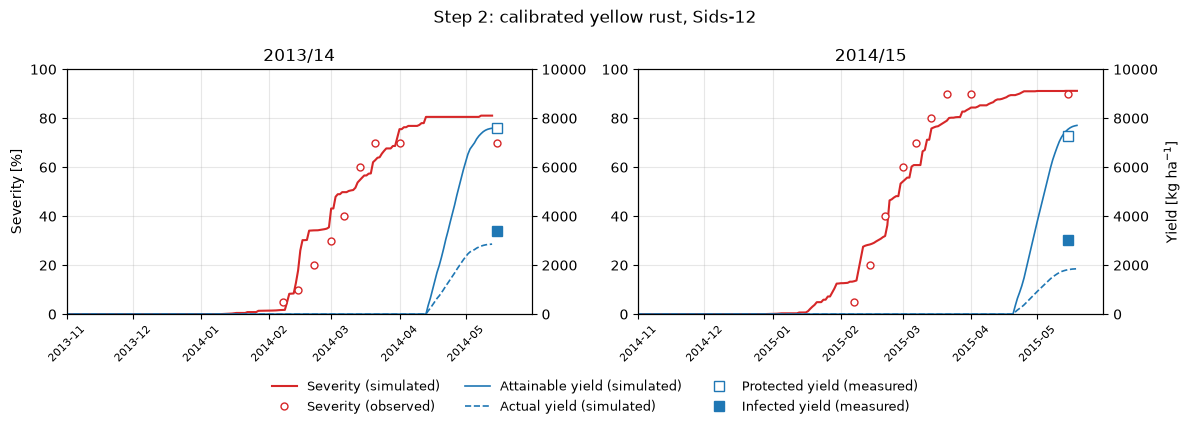

In [8]:
def plot_variety(ax, sim, variety, season, legend=False):
    """Simulated vs observed severity and yields of one cultivar-season."""
    s = sim[sim["GrowingSeason"] == season]
    r = ref_df[(ref_df["variety"] == variety) & (ref_df["year"] == season + 1)]
    ax.plot(s["Date"], s["DiseaseSeverity"], color="#d62728", lw=1.5, label="Severity (simulated)")
    sev = r.dropna(subset=["disease"])
    ax.plot(obs_dates(sev), sev["disease"], "o", color="#d62728", mfc="white", ms=5, label="Severity (observed)")
    ax.set_ylim(0, 100)
    ax2 = ax.twinx()
    ax2.plot(s["Date"], s["YieldAttainable"], color="#1f77b4", lw=1.2, label="Attainable yield (simulated)")
    ax2.plot(s["Date"], s["YieldActual"], color="#1f77b4", lw=1.2, ls="--", label="Actual yield (simulated)")
    y = r.dropna(subset=["yieldAttainable"])
    ax2.plot(obs_dates(y), y["yieldAttainable"], "s", color="#1f77b4", mfc="white", ms=7, label="Protected yield (measured)")
    ax2.plot(obs_dates(y), y["yieldActual"], "s", color="#1f77b4", ms=7, label="Infected yield (measured)")
    ax2.set_ylim(0, 10000)
    ax.set_xlim(pd.Timestamp(season, 11, 1), pd.Timestamp(season + 1, 5, 31))
    ax.tick_params(axis="x", rotation=45, labelsize=8)
    ax.grid(alpha=0.3)
    return ax2


fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
dis_sim = diag.simulation_frame(dis_res)
for ax, season in zip(axes, SEASONS):
    ax2 = plot_variety(ax, dis_sim, SUSCEPTIBLE, season)
    ax.set_title(f"{season}/{season + 1 - 2000:02d}")
axes[0].set_ylabel("Severity [%]")
ax2.set_ylabel("Yield [kg ha$^{-1}$]")
handles = axes[1].get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
fig.legend(handles, [h.get_label() for h in handles], loc="lower center", ncol=3, frameon=False, fontsize=9)
fig.suptitle("Step 2: calibrated yellow rust, Sids-12")
fig.tight_layout(rect=(0, 0.1, 1, 1))
plt.show()

## 5. Step 3 — extending to all cultivars

Every parameter is now fixed except two crop parameters, fitted per cultivar
against its severity and both yields (`calibration_variable="all"`):

- `RadiationUseEfficiency` sets the cultivar's attainable (protected) yield;
- `VarietalResistance` scales infection down (`1 − VarietalResistance`), so
  it sets how fast the epidemic grows on the cultivar.

The disease parameters, including the damage coefficient, are shared by all
cultivars, as in the vignette.

In [9]:
var_results = {}
for variety in VARIETIES:
    cfg = make_config(variety, disease_type="yellow_rust", calibration_variable="all", **CALIB)
    cfg.crop_parameters = copy.deepcopy(dis_cfg.crop_parameters)
    cfg.disease_parameters = copy.deepcopy(dis_cfg.disease_parameters)
    fr.deactivate_calibration(cfg.disease_parameters, list(cfg.disease_parameters))
    for name in ("RadiationUseEfficiency", "VarietalResistance"):
        cfg.crop_parameters[name]["calibration"] = True
    var_results[variety] = (cfg, run(cfg, variety))

pd.DataFrame({
    v: {"RMSE": res["outputs"]["summary"]["rmse"],
        **{k.split("_", 1)[1]: x for k, x in res["outputs"]["summary"]["best_params"].items()}}
    for v, (cfg, res) in var_results.items()
}).T.round(3)

- Calibrating 2 using Optuna (TPE), n_trials=999.
- Parameters:
['crop_RadiationUseEfficiency', 'crop_VarietalResistance']
- Evaluating trials in batches of 5 across 5 worker processes.


Best RMSE: 8.2340
{'crop_RadiationUseEfficiency': 3.062370500282735, 'crop_VarietalResistance': 6.14092108484528e-05}


- Calibrating 2 using Optuna (TPE), n_trials=999.
- Parameters:
['crop_RadiationUseEfficiency', 'crop_VarietalResistance']
- Evaluating trials in batches of 5 across 5 worker processes.


Best RMSE: 6.5110
{'crop_RadiationUseEfficiency': 3.090328063340362, 'crop_VarietalResistance': 0.0892440297260984}


- Calibrating 2 using Optuna (TPE), n_trials=999.
- Parameters:
['crop_RadiationUseEfficiency', 'crop_VarietalResistance']
- Evaluating trials in batches of 5 across 5 worker processes.


...

- Calibrating 2 using Optuna (TPE), n_trials=999.
- Parameters:
['crop_RadiationUseEfficiency', 'crop_VarietalResistance']
- Evaluating trials in batches of 5 across 5 worker processes.


Best RMSE: 5.5330
{'crop_RadiationUseEfficiency': 2.808532565973838, 'crop_VarietalResistance': 0.6517566723954836}


- Calibrating 2 using Optuna (TPE), n_trials=999.
- Parameters:
['crop_RadiationUseEfficiency', 'crop_VarietalResistance']
- Evaluating trials in batches of 5 across 5 worker processes.


Best RMSE: 4.1010
{'crop_RadiationUseEfficiency': 2.4035913935908946, 'crop_VarietalResistance': 0.804876360400424}


,RMSE,RadiationUseEfficiency,VarietalResistance
sids12,8.234,3.062,0.000
gem11,6.511,3.090,0.089
gem7,4.754,2.671,0.266
sids13,5.760,2.656,0.531
sids1,4.666,2.483,0.426
gem9,5.533,2.809,0.652
gem10,4.101,2.404,0.805


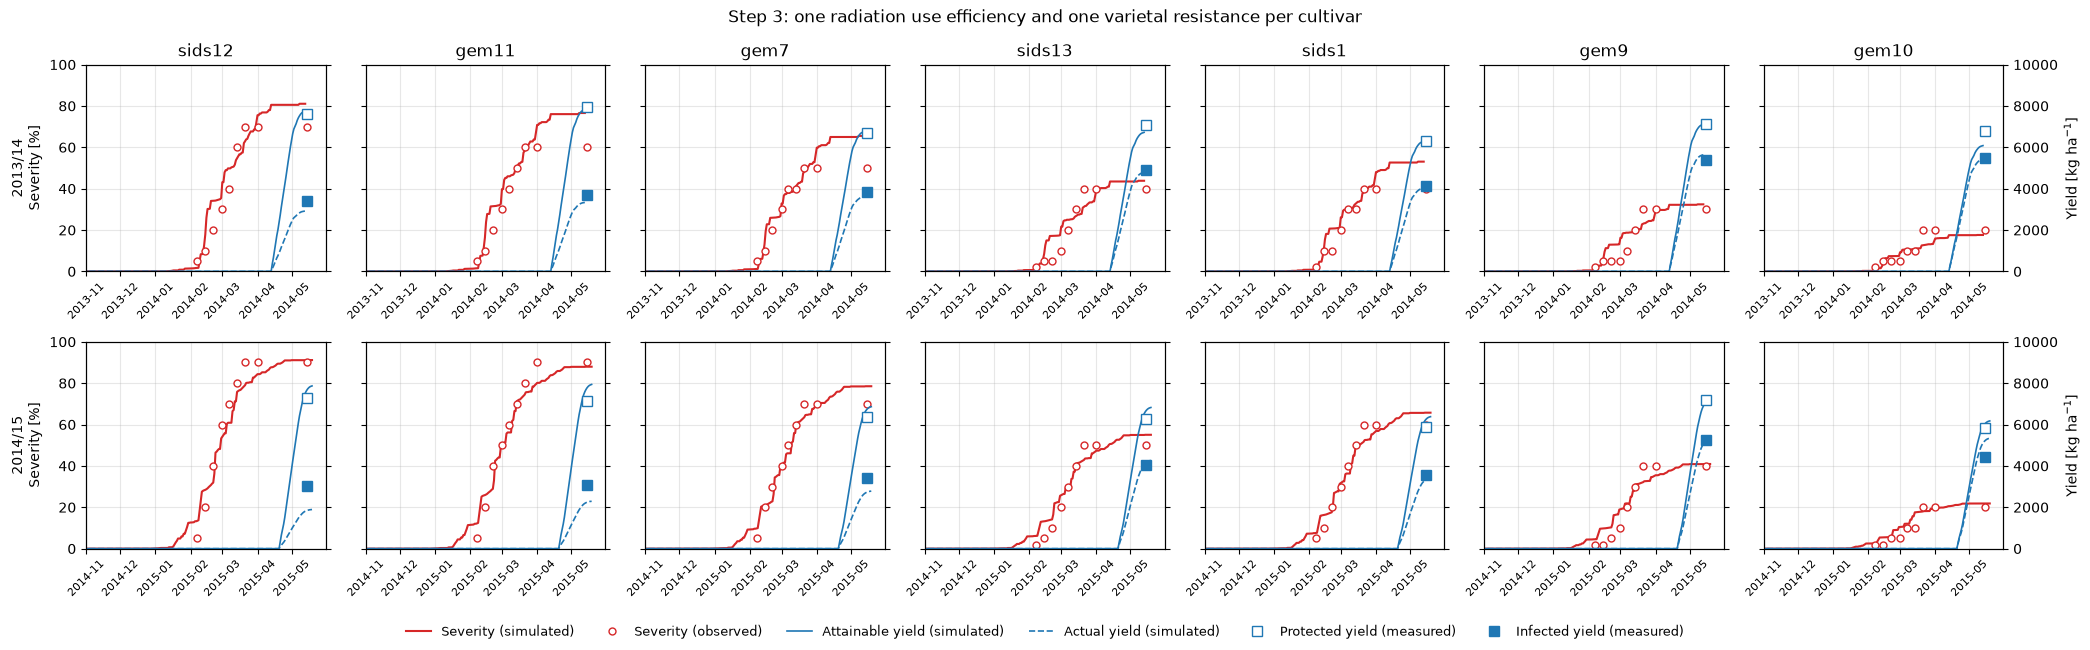

In [10]:
fig, axes = plt.subplots(2, len(VARIETIES), figsize=(3.0 * len(VARIETIES), 6.5), sharey=True)
for j, variety in enumerate(VARIETIES):
    sim = diag.simulation_frame(var_results[variety][1])
    for i, season in enumerate(SEASONS):
        ax2 = plot_variety(axes[i, j], sim, variety, season)
        if j < len(VARIETIES) - 1:
            ax2.set_yticklabels([])
        else:
            ax2.set_ylabel("Yield [kg ha$^{-1}$]")
    axes[0, j].set_title(variety)
for i, season in enumerate(SEASONS):
    axes[i, 0].set_ylabel(f"{season}/{season + 1 - 2000:02d}\nSeverity [%]")
handles = axes[0, 0].get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
fig.legend(handles, [h.get_label() for h in handles], loc="lower center", ncol=6, frameon=False, fontsize=9)
fig.suptitle("Step 3: one radiation use efficiency and one varietal resistance per cultivar")
fig.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

## 6. Simulated vs measured yield loss

The season summary of each cultivar gives its simulated attainable and actual
yield at maturity; the simulated loss is `(1 − actual / attainable) × 100`,
the same formula as the measured loss.

In [11]:
summary = pd.concat([
    fr.build_season_summary(diag.simulation_frame(res, severity_percent=False), "Sharkiya", v)
    .assign(variety=v)
    for v, (cfg, res) in var_results.items()
])
loss = (summary.rename(columns={"GrowingSeason": "season"})
        [["variety", "season", "YieldAttainable", "YieldActual", "YieldLossPerc"]]
        .merge(yield_obs[["variety", "season", "yieldAttainable", "yieldActual", "loss_measured"]],
               on=["variety", "season"]))
loss["loss_error"] = loss["YieldLossPerc"] - loss["loss_measured"]

stats = loss.groupby("season").apply(lambda d: pd.Series({
    "RMSE loss [%-pt]": np.sqrt((d["loss_error"] ** 2).mean()),
    "bias [%-pt]": d["loss_error"].mean(),
    "r": np.corrcoef(d["YieldLossPerc"], d["loss_measured"])[0, 1],
}), include_groups=False)
display(stats.round(2))
loss.set_index(["variety", "season"]).loc[VARIETIES].round(1)

,RMSE loss [%-pt],bias [%-pt],r
season,,,
2013,4.78,0.31,1.00
2014,10.96,6.21,0.99


YieldAttainable  YieldActual  YieldLossPerc  yieldAttainable  \
variety season                                                                 
sids12  2013             7750.3       2919.3           62.3           7607.1   
        2014             7867.5       1891.3           76.0           7285.7   
gem11   2013             7821.0       3334.5           57.4           7964.3   
        2014             7939.3       2290.9           71.1           7142.9   
gem7    2013             6761.0       3614.8           46.5           6678.6   
        2014             6863.3       2782.2           59.5           6357.1   
sids13  2013             6722.8       4783.6           28.8           7071.4   
        2014             6824.5       4263.7           37.5           6250.0   
sids1   2013             6285.1       4024.3           36.0           6321.4   
        2014             6380.2       3400.2           46.7           5892.9   
gem9    2013             7107.8       5637.1           20.7           7107.1   
        2014             7215.4       5290.4           26.7           7178.6   
gem10   2013             6083.0       5422.4           10.9           6785.7   
        2014             6175.0       5337.1           13.6           5821.4   

                yieldActual  loss_measured  loss_error  
variety season                                          
sids12  2013         3392.9           55.4         6.9  
        2014         3035.7           58.3        17.6  
gem11   2013         3714.3           53.4         4.0  
        2014         3071.4           57.0        14.1  
gem7    2013         3821.4           42.8         3.8  
        2014         3392.9           46.6        12.8  
sids13  2013         4892.9           30.8        -2.0  
        2014         4035.7           35.4         2.1  
sids1   2013         4107.1           35.0         0.9  
        2014         3571.4           39.4         7.3  
gem9    2013         5392.9           24.1        -3.4  
        2014         5250.0           26.9        -0.2  
gem10   2013         5500.0           18.9        -8.1  
        2014         4428.6           23.9       -10.4

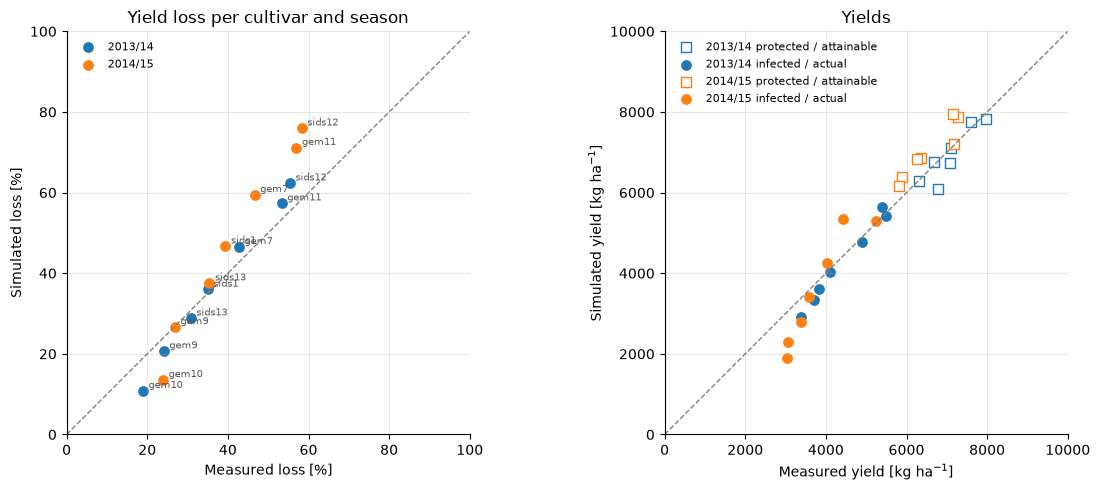

In [12]:
season_colors = {2013: "#1f77b4", 2014: "#ff7f0e"}
fig, (ax_l, ax_y) = plt.subplots(1, 2, figsize=(12, 5))

for season, d in loss.groupby("season"):
    label = f"{season}/{season + 1 - 2000:02d}"
    ax_l.scatter(d["loss_measured"], d["YieldLossPerc"], color=season_colors[season], s=45, label=label)
    for _, row in d.iterrows():
        ax_l.annotate(row["variety"], (row["loss_measured"], row["YieldLossPerc"]),
                      xytext=(4, 2), textcoords="offset points", fontsize=7, color="0.35")
    ax_y.scatter(d["yieldAttainable"], d["YieldAttainable"], color=season_colors[season], marker="s",
                 facecolors="white", s=45, label=f"{label} protected / attainable")
    ax_y.scatter(d["yieldActual"], d["YieldActual"], color=season_colors[season], s=45,
                 label=f"{label} infected / actual")

ax_l.plot([0, 100], [0, 100], color="0.5", lw=1, ls="--")
ax_l.set(xlim=(0, 100), ylim=(0, 100), xlabel="Measured loss [%]", ylabel="Simulated loss [%]",
         title="Yield loss per cultivar and season")
ax_y.plot([0, 10000], [0, 10000], color="0.5", lw=1, ls="--")
ax_y.set(xlim=(0, 10000), ylim=(0, 10000), xlabel="Measured yield [kg ha$^{-1}$]",
         ylabel="Simulated yield [kg ha$^{-1}$]", title="Yields")
for ax in (ax_l, ax_y):
    ax.set_aspect("equal")
    ax.grid(alpha=0.3)
    ax.legend(frameon=False, fontsize=8, loc="upper left")
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
fig.tight_layout()
plt.show()

In [13]:
# Severity fit per cultivar: RMSE over the observation dates the season simulates.
sev_rmse = {}
for v, (cfg, res) in var_results.items():
    err = diag.match_ref_to_sim(diag.simulation_frame(res), ref_df[ref_df["variety"] == v],
                                SEASONS, "disease", "DiseaseSeverity")
    sev_rmse[v] = err.groupby("season")["error"].apply(lambda e: np.sqrt((e ** 2).mean()))
pd.DataFrame(sev_rmse).T.round(1).rename(columns=lambda s: f"severity RMSE {s}/{s + 1 - 2000:02d}")

season,severity RMSE 2013/14,severity RMSE 2014/15
sids12,9.0,7.4
gem11,7.4,6.3
gem7,4.7,4.8
sids13,7.2,4.9
sids1,5.4,4.5
gem9,6.3,5.4
gem10,3.6,3.5


## 7. Summary and limits

**Crop (step 1).** A `CycleLength` of 3628 °C d (sowing to DOY 135) puts
maturity on 13 May 2014 and 19 May 2015. The six canopy and partitioning
parameters reproduce the two protected-plot yields of Sids-12 (objective
1.09). `PartitioningMaximum` sits on its lower bound (0.80) and
`FloweringStart` near its upper one (83 % of the cycle), so grain filling
covers only the last month of the cycle. The data hold no flowering date to
check this against.

**Disease (step 2).** The calibrated epidemic follows the observed severity of
Sids-12 with an RMSE of 9.0 (2013/14) and 7.4 (2014/15) severity points.
`LightStealerDamage` came out at 0.60, close to its lower bound (0.5). Four
other parameters sit on a bound (`WetnessDurationMinimum`,
`RelativeHumidityCritical` and `Rain50Detachment` low, `LatencyDuration`
high), so their values should not be read as estimates.

**Cultivars (step 3).** `VarietalResistance` orders the cultivars from Sids-12
(0.00) to Gem-10 (0.80), the order of the paper's final severity and AUDPC
(Table 1). `RadiationUseEfficiency` ranges from 2.4 to 3.1. Severity RMSE is
3.5–9.0 points per cultivar-season.

**Yield loss (section 6).**

- 2013/14: simulated loss within 8.1 points of the measured loss for every
  cultivar (RMSE 4.8 points, bias +0.3).
- 2014/15: RMSE 11.0 points, bias +6.2. The three most susceptible cultivars
  are overestimated (Sids-12 76 against 58 %, Gem-11 71 against 57 %, Gem-7 60
  against 47 %).
- Gem-10 is underestimated in both seasons (11 and 14 against 19 and 24 %).
- The correlation of about 1.0 within each season mostly says that simulated
  and measured loss both follow the cultivars' resistance. It is not evidence
  that the model predicts loss.

The two seasons need different damage. Observed severity was higher in
2014/15 (Sids-12 90 against 70 %), but the measured loss only rose by 3 points
(55 to 58 %). The model turns the extra severity into 14 more points of loss
(62 to 76 %). One damage coefficient, shared by all cultivars and seasons,
cannot match both.

**Limits.**

1. The loss is fitted, not predicted: both yields of every cultivar-season are
   calibration targets. A hold-out (calibrate on one season, predict the other)
   would test it, but it is not done here.
2. Sowing on DOY 300 and harvest on DOY 135 are assumptions; the paper gives
   neither date. The `fint` values are placeholders.
3. Weather is gridded (NASA POWER / MERRA-2), radiation is estimated from the
   temperature range, and hourly humidity and leaf wetness are synthesised.
4. Two seasons at one site, three replicates per treatment in the paper.
5. Measured yields are grain at market moisture (ardab feddan⁻¹); the model's
   yield is not tied to a moisture content. The loss, a ratio, is not affected.
6. `score_harvest_after_maturity` is a simpest option that is not in the C#
   model.